#TP2 - PROCESAMIENTO DEL HABLA : Análisis de documentos PDF

##Alumna: Carrillo, Julia Belén





**INTRODUCCION**

En este trabajo práctico voy a trabajar con el informe "Acceso y uso de tecnologías de la información y la comunicación. EPH. Cuarto trimestre de 2024", publicado por el Instituto Nacional de Estadística y Censos (INDEC) en mayo de 2025.

El documento presenta información estadística sobre el acceso a internet y computadoras en los hogares urbanos de Argentina, así como sobre el uso de celulares, computadoras e internet por parte de la población.

**1. Adquisición y metadatos**

Descarga: Utilizando las librerías requests o urllib, descarga un archivo PDF desde un enlace público (por ejemplo, un artículo científico de arXiv o un reporte institucional).

No puede usar el mismo pdf o enlace que otra persona ya haya presentado en el foro. El PDF elegido debe contener texto extraible, no deben ser páginas escaneadas tipo imagen.

Inspección: Muestra por pantalla los metadatos del archivo: título, autor, número de páginas y software de creación.

Sugerencia: Puedes utilizar librerías como PyMuPDF (fitz) o PyPDF2.

Decidí trabajar con la biblioteca `pdfplumber` porque ofrece herramientas específicas para identificar y extraer datos tabulares de manera más sencilla, y me resultaron mas adecuadas para realizar los ejercicios de las consignas.

In [3]:
#Instalo las bibliotecas
!pip install "pillow>=8.0,<13.0" -q

In [4]:
!pip install pdfplumber pandas requests -q

In [34]:
#Importo las librerías que voy a usar
import pdfplumber
import pandas as pd
import requests
import os

#Descargo el PDF

URL_PDF = "https://www.indec.gob.ar/uploads/informesdeprensa/mautic_05_25FD0D0C4A71.pdf"

NOMBRE_ARCHIVO = "Acceso_y_uso_de_tecnologias.pdf"

respuesta = requests.get(URL_PDF)

#Corroboro la solucitud
print("Código de estado HTTP: ", respuesta.status_code)

Código de estado HTTP:  200


In [35]:
#Guardo el archivo

with open(NOMBRE_ARCHIVO, "wb") as f:
  f.write(respuesta.content)

print(f"Archivo guardado como '{NOMBRE_ARCHIVO}'")

Archivo guardado como 'Acceso_y_uso_de_tecnologias.pdf'


In [36]:
#Abro el PDF
pdf_plumber = pdfplumber.open(NOMBRE_ARCHIVO)

print("Tipo de objeto: ", type(pdf_plumber))
print("Cantidad de páginas: ", len(pdf_plumber.pages))

Tipo de objeto:  <class 'pdfplumber.pdf.PDF'>
Cantidad de páginas:  15


In [37]:
#Obtengo y muestro la metadata
metadata = pdf_plumber.metadata
metadata

{'Author': 'INDEC',
 'CreationDate': "D:20250515143102-03'00'",
 'Creator': 'Adobe InDesign 20.3 (Windows)',
 'ModDate': "D:20250515143104-03'00'",
 'Producer': 'Adobe PDF Library 17.0',
 'Subject': 'Acceso y uso de tecnologías de la información y la comunicación. Encuesta Permanente de Hogares. ',
 'Title': 'Acceso y uso de tecnologías de la información y la comunicación. EPH. Cuarto trimestre de 2024',
 'Trapped': 'False'}

**2. Análisis estructural del texto**

Extracción cruda: Extrae el texto del PDF.. Identifica la función de la librería elegida que te ayuda en esta tarea y te permite ver el texto extraído lo más crudo posible.

Análisis de separadores: Observa y describe cómo están separados los párrafos, las secciones y los capítulos.

Identificación de caracteres: ¿Qué caracteres especiales funcionan como separadores de línea o de bloque en este archivo específico? (Ej: \n, \r, \t o secuencias de espacios).

In [39]:
#Extraigo el texto del documento
texto_completo = ""

for pagina in pdf_plumber.pages:
  texto_pagina = pagina.extract_text()
  if texto_pagina:
    texto_completo += texto_pagina + "\n"

print(texto_completo[:500])

Informes técnicos / Vol. 9, n° 113 ISSN 2545-6636
Ciencia y tecnología
Vol. 9, n° 1
Acceso y uso de tecnologías de la
información y la comunicación. EPH
Cuarto trimestre de 2024
Informes Técnicos. Vol. 9, nº 113
Índice Pág.
ISSN 2545-6636
Gráficos
Ciencia y tecnología. Vol. 9, nº 1
Gráfico 1. Hogares con acceso a computadora e internet.
Total 31 aglomerados urbanos. Cuarto trimestre de 2024 ........................3
Acceso y uso de tecnologías de la información y la
comunicación. EPH Gráfico 2. 


In [40]:
#Analizo cómo estan separados los párrafos
print(repr(texto_completo[:500]))

'Informes técnicos / Vol. 9, n° 113 ISSN 2545-6636\nCiencia y tecnología\nVol. 9, n° 1\nAcceso y uso de tecnologías de la\ninformación y la comunicación. EPH\nCuarto trimestre de 2024\nInformes Técnicos. Vol. 9, nº 113\nÍndice Pág.\nISSN 2545-6636\nGráficos\nCiencia y tecnología. Vol. 9, nº 1\nGráfico 1. Hogares con acceso a computadora e internet.\nTotal 31 aglomerados urbanos. Cuarto trimestre de 2024 ........................3\nAcceso y uso de tecnologías de la información y la\ncomunicación. EPH Gráfico 2. '


In [12]:
#Quiero ver con que otros caracteres estan separados los párrafos, secciones y capítulos

print("Saltos de línea:", texto_completo.count("\n"))
print("Líneas en blanco:", texto_completo.count("\n\n"))
print("Tabulaciones:", texto_completo.count("\t"))
print("Retornos de carro:", texto_completo.count("\r"))
print("Saltos de página:", texto_completo.count("\f"))
print("Espacios:", texto_completo.count(" "))
print("Espacios no separables:", texto_completo.count("\xa0"))

Saltos de línea: 596
Líneas en blanco: 0
Tabulaciones: 0
Retornos de carro: 0
Saltos de página: 0
Espacios: 5021
Espacios no separables: 0


Podemos ver que el principal separador es el salto de línea (\n), con 596 apariciones, seguido de los espacios comunes, con 5.021 apariciones.

No se encontraron saltos de línea dobles (\n\n), tabulaciones (\t), retornos de carro (\r), saltos de página (\f) ni espacios no separables (\xa0).

Es decir que el texto extraído utiliza principalmente saltos de línea para separar su contenido, sin distinguir claramente los párrafos, títulos o secciones mediante caracteres especiales diferentes.

Además, como al concatenar las páginas agregué manualmente un salto de línea, parte de los 596 saltos contabilizados fueron incorporados durante la extracción.

**3. Extracción de datos tabulares**


Busca una página en el PDF que contenga una tabla de datos.

Extrae dicha tabla y conviértela en un DataFrame de Pandas.

Realiza una limpieza básica de la tabla (nombrar columnas, eliminar filas vacías).

Sugerencia: Se recomienda el uso de pdfplumber o tabula-py.

In [13]:
#Extracción de datos tabulares, voy a trabajar con la tabla que aparece en la página 4

cuarta_pagina = pdf_plumber.pages[3]
tabla_cruda = cuarta_pagina.extract_table()

print("Tipo de dato: ", type(tabla_cruda))
print("Cantidad de filas: ", len(tabla_cruda))
print("Primeras 3 filas: ")
for fila in tabla_cruda[:3]:
  print(fila)

Tipo de dato:  <class 'list'>
Cantidad de filas:  43
Primeras 3 filas: 
['Total 31 aglomerados urbanos', '60,3', '39,7', '0,0', '93,7', '6,3', '0,0']
['Aglomerados del interior', '56,6', '43,4', '0,0', '93,6', '6,4', '0,0']
['Regiones', '', '', '', '', '', '']


No me esta leyendo el encabezado de la tabla, voy a corroborar si pdfplumber esta extrayendo correctamente todos los datos de la tabla

In [17]:
texto_pagina = cuarta_pagina.extract_text()
print(texto_pagina[:500])

1. Resultados del cuarto trimestre de 2024
Cuadro 1. Hogares con acceso a bienes y servicios de las TIC (computadora e internet). Total 31 aglomerados urbanos.
Cuarto trimestre de 2024
Bienes de las TIC
Área geográfica Computadora Internet
Sí No Ns/Nr Sí No Ns/Nr
Porcentaje
Total 31 aglomerados urbanos 60,3 39,7 0,0 93,7 6,3 0,0
Aglomerados del interior 56,6 43,4 0,0 93,6 6,4 0,0
Regiones
Gran Buenos Aires 63,6 36,4 0,0 93,8 6,1 0,0
Ciudad Autónoma de Buenos Aires 85,4 14,6 0,0 96,2 3,8 0,0
Part


Vemos que el encabezado aparece en el texto, osea q pdfplumber lo lee, procederé a agregar los encabezados manualmente.

In [18]:
#Creo el DataFrame
columnas = [
    "Área geográfica",
    "Computadora Sí",
    "Computadora No",
    "Computadora Ns/Nr",
    "Internet Sí",
    "Internet No",
    "Internet Ns/Nr"
]

df = pd.DataFrame(tabla_cruda, columns=columnas)

display(df.head())

,Área geográfica,Computadora Sí,Computadora No,Computadora Ns/Nr,Internet Sí,Internet No,Internet Ns/Nr
0,Total 31 aglomerados urbanos,"60,3","39,7","0,0","93,7","6,3","0,0"
1,Aglomerados del interior,"56,6","43,4","0,0","93,6","6,4","0,0"
2,Regiones,,,,,,
3,Gran Buenos Aires,"63,6","36,4","0,0","93,8","6,1","0,0"
4,Ciudad Autónoma de Buenos Aires,"85,4","14,6","0,0","96,2","3,8","0,0"


Acá ya veo que la tercer fila de la tabla esta vacía, no tiene elementos nulos, simplemente esta vacía, por lo que `dropna()` no va a eliminarla, entonces voy a rellenar las filas vacías por valores nulos para luego poder eliminarlas. Pero antes voy a verificar si hay mas filas vacías.

In [20]:
#Prompt: Mostrar las filas que contienen al menos un elemento vacío
df[df.eq('').any(axis=1) | df.isna().any(axis=1)]

,Área geográfica,Computadora Sí,Computadora No,Computadora Ns/Nr,Internet Sí,Internet No,Internet Ns/Nr
2,Regiones,,,,,,


In [22]:
#Prompt: Reemplazo las cadenas vacías por valores nulos
df = df.replace('', pd.NA)

#Elimino las filas que no tienen datos numéricos
df = df.dropna(subset=columnas[1:], how='all')

#Reorganizo los índices
df = df.reset_index(drop=True)

display(df.head())

,Área geográfica,Computadora Sí,Computadora No,Computadora Ns/Nr,Internet Sí,Internet No,Internet Ns/Nr
0,Total 31 aglomerados urbanos,"60,3","39,7","0,0","93,7","6,3","0,0"
1,Aglomerados del interior,"56,6","43,4","0,0","93,6","6,4","0,0"
2,Gran Buenos Aires,"63,6","36,4","0,0","93,8","6,1","0,0"
3,Ciudad Autónoma de Buenos Aires,"85,4","14,6","0,0","96,2","3,8","0,0"
4,Partidos del Gran Buenos Aires,"57,0","43,0","0,0","93,0","6,9","0,0"


**4. Análisis de frecuencias (NLP básico)**

Elige una página que contenga únicamente texto narrativo, usa la biblioteca nltk o spacy  y realiza lo siguiente:

Tokenización: Extrae el texto y conviértelo a minúsculas.

Limpieza: Elimina las stop words (palabras funcionales sin peso semántico como "el", "de", "y") y signos de puntuación.

Visualización: Genera un gráfico de barras que muestre las 15 palabras más frecuentes en esa página. ¿ Te surgieron en esta visualización tokens que también considerarías stop words? Comenta y justifica.

Elijo la página 15 que sólo contiene texto narrativo.

In [23]:
#Selecciono una página con texto narrativo
pagina_narrativa = pdf_plumber.pages[14]

#Extraigo el texto y lo convierto a minúsculas
texto_narrativo = pagina_narrativa.extract_text().lower()

print(texto_narrativo[:1000])

3.3 definiciones básicas
teléfono móvil o celular: teléfono portátil abonado a un servicio de telefonía móvil que utiliza tec-
nologías celulares. comprende los sistemas y tecnologías celulares analógicos y digitales con línea.
quedan comprendidos todos los tipos de abonados.
computadora: equipo de computación en el hogar; incluye computadoras de escritorio, portátiles
(notebook y netbook), y tabletas electrónicas en condiciones de uso. se excluyen otros dispositivos
tales como agendas digitales personales y equipos que reúnen algunas de las funcionalidades de
las computadoras, como teléfonos móviles, consolas de juegos o aparatos de televisión inteligentes.
internet: red informática mundial de acceso a servicios de información, comunicación, producción
y transferencia de contenidos, incluyendo web (www). no incluye redes internas de computadoras
o intranet. remite al acceso a internet en el hogar. el acceso puede ser a través de una red fija o
móvil, ya sea distribuido en forma alámbr

In [24]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

#Obtenemos las stopwords en español
stopwords_es = set(stopwords.words('spanish'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [27]:
#Elimino signos de puntuación
import string

texto_limpio = ''.join(c for c in texto_narrativo if c not in string.punctuation)
print(texto_limpio)

33 definiciones básicas
teléfono móvil o celular teléfono portátil abonado a un servicio de telefonía móvil que utiliza tec
nologías celulares comprende los sistemas y tecnologías celulares analógicos y digitales con línea
quedan comprendidos todos los tipos de abonados
computadora equipo de computación en el hogar incluye computadoras de escritorio portátiles
notebook y netbook y tabletas electrónicas en condiciones de uso se excluyen otros dispositivos
tales como agendas digitales personales y equipos que reúnen algunas de las funcionalidades de
las computadoras como teléfonos móviles consolas de juegos o aparatos de televisión inteligentes
internet red informática mundial de acceso a servicios de información comunicación producción
y transferencia de contenidos incluyendo web www no incluye redes internas de computadoras
o intranet remite al acceso a internet en el hogar el acceso puede ser a través de una red fija o
móvil ya sea distribuido en forma alámbrica o inalámbrica incluye 

In [29]:
#Elimino caracteres extraños

import re

def quitar_caracteres(texto):
  return re.sub(r'[^\w\s]', '', texto)

texto_limpio = quitar_caracteres(texto_limpio)
print(texto_limpio)

33 definiciones básicas
teléfono móvil o celular teléfono portátil abonado a un servicio de telefonía móvil que utiliza tec
nologías celulares comprende los sistemas y tecnologías celulares analógicos y digitales con línea
quedan comprendidos todos los tipos de abonados
computadora equipo de computación en el hogar incluye computadoras de escritorio portátiles
notebook y netbook y tabletas electrónicas en condiciones de uso se excluyen otros dispositivos
tales como agendas digitales personales y equipos que reúnen algunas de las funcionalidades de
las computadoras como teléfonos móviles consolas de juegos o aparatos de televisión inteligentes
internet red informática mundial de acceso a servicios de información comunicación producción
y transferencia de contenidos incluyendo web www no incluye redes internas de computadoras
o intranet remite al acceso a internet en el hogar el acceso puede ser a través de una red fija o
móvil ya sea distribuido en forma alámbrica o inalámbrica incluye 

In [30]:
# Elimino las stopwords

#Primero separo el texto en palabras
palabras = texto_limpio.split()

filtradas = [p for p in palabras if p not in stopwords_es]

print(filtradas)

['33', 'definiciones', 'básicas', 'teléfono', 'móvil', 'celular', 'teléfono', 'portátil', 'abonado', 'servicio', 'telefonía', 'móvil', 'utiliza', 'tec', 'nologías', 'celulares', 'comprende', 'sistemas', 'tecnologías', 'celulares', 'analógicos', 'digitales', 'línea', 'quedan', 'comprendidos', 'tipos', 'abonados', 'computadora', 'equipo', 'computación', 'hogar', 'incluye', 'computadoras', 'escritorio', 'portátiles', 'notebook', 'netbook', 'tabletas', 'electrónicas', 'condiciones', 'uso', 'excluyen', 'dispositivos', 'tales', 'agendas', 'digitales', 'personales', 'equipos', 'reúnen', 'funcionalidades', 'computadoras', 'teléfonos', 'móviles', 'consolas', 'juegos', 'aparatos', 'televisión', 'inteligentes', 'internet', 'red', 'informática', 'mundial', 'acceso', 'servicios', 'información', 'comunicación', 'producción', 'transferencia', 'contenidos', 'incluyendo', 'web', 'www', 'incluye', 'redes', 'internas', 'computadoras', 'intranet', 'remite', 'acceso', 'internet', 'hogar', 'acceso', 'puede'

Para armar el gráfico voy a identificar las 15 palabras mas frecuentes para poder armarlo

In [31]:
#Cuento las 15 palabras más frecuentes
frecuencias = pd.Series(filtradas).value_counts().head(15)

print(frecuencias)

hogar           9
acceso          7
tic             6
servicios       5
uso             5
bienes          4
2024            4
móvil           4
computadoras    3
referencia      3
incluye         3
información     3
comunicación    3
período         3
tecnologías     3
Name: count, dtype: int64


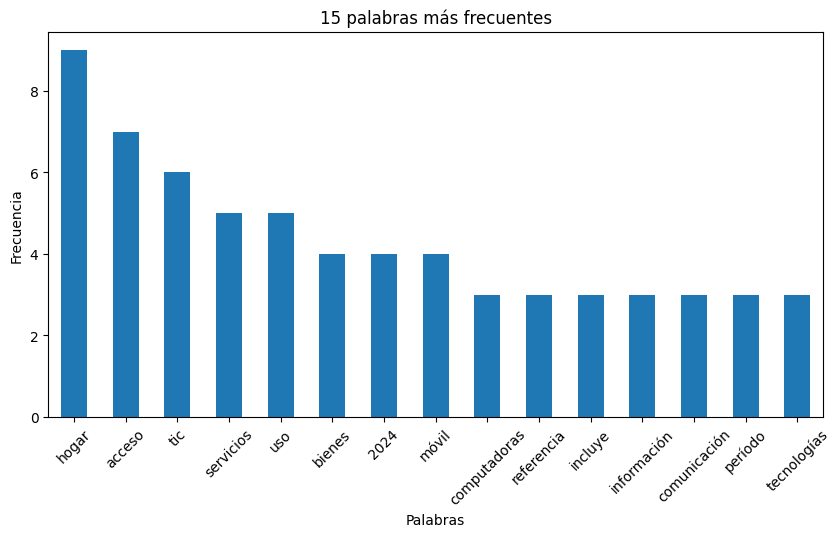

In [33]:
import matplotlib.pyplot as plt

#Grafico las 15 palabras más frecuentes
frecuencias.plot(kind='bar', figsize=(10, 5))

plt.title("15 palabras más frecuentes")
plt.xlabel("Palabras")
plt.ylabel("Frecuencia")
plt.xticks(rotation=45)
plt.show()

Al analizar las frecuencias, se observa que las palabras más utilizadas son "hogar", "acceso" y "tic", lo cual es coherente con el contenido del informe, que trata sobre el acceso y uso de tecnologías de la información y la comunicación en los hogares.

La eliminación de stopwords permitió identificar con mayor claridad los términos relevantes del texto. También aparecen palabras como "2024", "referencia" y "período", que aportan información contextual, aunque no representan los conceptos principales del informe.

En este top 15 no encontré ninguna palabra que considerara una stopword. La única duda que tuve fue si debía eliminar "2024", que aparece 4 veces. Decidí no hacerlo porque, aunque es un número, representa un año, una fecha, y aporta información sobre el período al que corresponden los datos del informe.

In [42]:
#Cierro el archivo PDF

pdf_plumber.close()

print("Documento cerrado correctamente")

Documento cerrado correctamente


##Fuentes utilizadas:

Apunte de la clase 3, notebook:

PH_taller_intro_pdfs_2026-09-07_parte_1.ipynb

Chat GPT:
https://chatgpt.com/share/6ad67977-e038-83ea-9b16-2739a9a8cbbe
